# Next-Word Story Generation on TinyStories with RNN, BiRNN, LSTM and GRU

**Course:** Foundations of Generative AI (ICT4403), Assignment 2
**Name:** K Liya &nbsp;&nbsp; **Reg. No.:** 230953118 &nbsp;&nbsp; **Section:** F

Dataset: **TinyStories** (Eldan and Li, 2023), a large collection of short, simple children's stories created specifically for training and studying small language models. Every story uses vocabulary a 3 to 4 year old would understand, which makes it a good fit for comparing small recurrent next-word models.

The notebook follows the three parts of the question:
- **Part (i)** dataset, preprocessing, sequence building, model training
- **Part (ii)** quantitative + qualitative comparison
- **Part (iii)** temperature sampling and choosing the best model

**Kaggle settings:** Accelerator = GPU (T4 or P100), Internet = On. Each model trains for up to 10 epochs with early stopping. On a Kaggle T4 the four models trained for 33 minutes in total and the whole notebook ran in about 34 minutes.

In [1]:
import os
import re
import sys
import math
import time
import random
import subprocess
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn

try:
    from datasets import load_dataset
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "datasets"], check=True)
    from datasets import load_dataset

In [2]:
CFG = dict(
    seed=2024,
    n_train_stories=15000,   # subset of the 2.1M training stories
    n_eval_stories=3000,     # taken from the official validation split, half for validation, half for test
    seq_len=16,              # tokens of context per example
    min_count=5,             # rarer words -> <unk>
    emb_dim=200,
    hidden=512,
    dropout=0.25,
    batch_size=512,
    lr=1e-3,
    max_epochs=10,
    patience=2,              # early stopping on val loss
)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)

set_seed(CFG["seed"])
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
AMP = DEVICE == "cuda"
SAVE_DIR = "/kaggle/working" if os.path.exists("/kaggle/working") else "results"
os.makedirs(SAVE_DIR, exist_ok=True)
print(DEVICE, torch.cuda.get_device_name(0) if AMP else "")

cuda Tesla T4


---
## Part (i): Dataset, preprocessing and training

### Loading the stories
- Hugging Face: https://huggingface.co/datasets/roneneldan/TinyStories
- Paper: *TinyStories: How Small Can Language Models Be and Still Speak Coherent English?* https://arxiv.org/abs/2305.07759

The full training split has about 2.1 million stories, far more than four models can be trained on in a reasonable time on one GPU. I stream the first 15,000 training stories, plus the first 3,000 stories of the official validation split, which I divide into a validation half (for early stopping) and a test half (only for the final numbers).

In [3]:
train_stream = load_dataset("roneneldan/TinyStories", split="train", streaming=True)
eval_stream = load_dataset("roneneldan/TinyStories", split="validation", streaming=True)
train_texts = [ex["text"] for ex in train_stream.take(CFG["n_train_stories"])]
eval_texts = [ex["text"] for ex in eval_stream.take(CFG["n_eval_stories"])]
val_texts = eval_texts[: len(eval_texts) // 2]
test_texts = eval_texts[len(eval_texts) // 2:]
print(len(train_texts), "train |", len(val_texts), "validation |", len(test_texts), "test stories\n")
print(train_texts[0])
print("-" * 60)
print(train_texts[1])

15000 train | 1500 validation | 1500 test stories

One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for sharing the needle and fixing her shirt. They both felt happy because they had shared and worked together.
------------------------------------------------------------
Once upon a time, there was a little car named Beep. Beep loved to go fast and play in the sun. Beep was a healthy car because he always had good fuel. Good fuel made Beep happy and stro

In [4]:
story_len = [len(t.split()) for t in train_texts]
all_words = re.findall(r"[a-z']+", " ".join(train_texts).lower())
freq = Counter(all_words)
names_found = Counter(w for w in re.findall(r"\b[A-Z][a-z]+\b", " ".join(train_texts))
                      if w.lower() not in {"once", "one", "the", "she", "he", "they", "it", "but", "then",
                                           "when", "i", "after", "so", "we", "you", "a", "her", "his",
                                           "this", "there", "every", "suddenly", "as", "at", "in", "from",
                                           "finally", "together", "mom", "dad", "mommy", "daddy", "yes", "no", "and"})

print("stories                   :", len(train_texts))
print("total words               :", len(all_words))
print("distinct words            :", len(freq))
print("hapax (seen once)         :", sum(c == 1 for c in freq.values()))
print("story length min/median/max:", min(story_len), int(np.median(story_len)), max(story_len))
print("stories starting 'Once upon a time':", sum(t.strip().lower().startswith("once upon a time") for t in train_texts))
print("\nmost common words:", freq.most_common(15))
print("most common character names:", names_found.most_common(10))

stories                   : 15000
total words               : 2617830
distinct words            : 10937
hapax (seen once)         : 2551
story length min/median/max: 43 152 878
stories starting 'Once upon a time': 9131

most common words: [('the', 141706), ('and', 126736), ('to', 88799), ('a', 81312), ('was', 65317), ('he', 54950), ('she', 54266), ('they', 46304), ('it', 46215), ('her', 35520), ('said', 26519), ('you', 23226), ('in', 22787), ('his', 22723), ('with', 22411)]
most common character names: [('Lily', 22584), ('Ben', 8091), ('Tom', 7628), ('Timmy', 7095), ('Tim', 4652), ('Sam', 3316), ('Max', 3297), ('Anna', 3136), ('Jack', 2670), ('Let', 2340)]


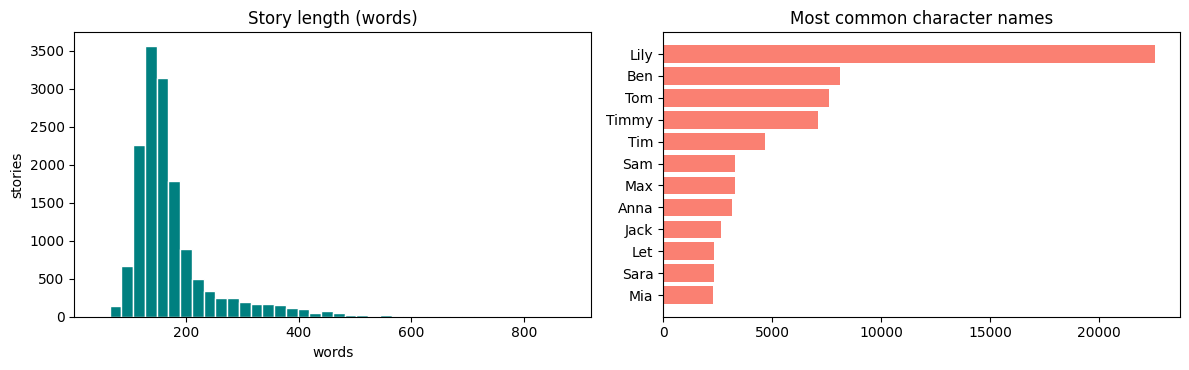

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(story_len, bins=40, color="teal", edgecolor="white")
axes[0].set_title("Story length (words)")
axes[0].set_xlabel("words"); axes[0].set_ylabel("stories")
top_names = names_found.most_common(12)
axes[1].barh([n for n, _ in top_names][::-1], [c for _, c in top_names][::-1], color="salmon")
axes[1].set_title("Most common character names")
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/dataset_overview.png", dpi=110)
plt.show()

**What the data looks like.** The 15,000 training stories contain about 2.6 million words. They are short (median 152 words, between 43 and 878) and follow very similar patterns. 9,131 of them (61%) start with *"Once upon a time"*, a character is introduced (very often *"a little girl named Lily"*), something small happens, and there is a simple ending or moral. The vocabulary is deliberately small: only 10,937 distinct words, and just 2,551 of them appear once, which is tiny compared with news or Wikipedia text. A handful of names dominate: *Lily* alone appears 22,584 times, followed by *Ben*, *Tom* and *Timmy*. (*Let* shows up in the name chart only because my simple capital-letter check also catches *"Let's"* at the start of a sentence.) There is a lot of short dialogue with *said*. All this makes the next word much more predictable than in most real text, but the stories still have characters and small plots, so it's a fair test of whether a model can keep track of the context.

### Cleaning and tokenising
- normalise curly quotes and apostrophes to plain ones
- lowercase, keep words (with apostrophes, so `didn't` and `lily's` stay whole) and `. , ! ?` as separate tokens. Quote marks are dropped
- words with fewer than 5 occurrences in the training stories become `<unk>`

In [6]:
def clean_tokens(text):
    text = text.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')
    text = re.sub(r"[-_]+", " ", text.lower())
    return re.findall(r"[a-z]+(?:'[a-z]+)*|[.,!?]", text)

train_stories = [clean_tokens(t) for t in train_texts]
val_stories = [clean_tokens(t) for t in val_texts]
test_stories = [clean_tokens(t) for t in test_texts]

counter = Counter(w for s in train_stories for w in s)
idx2word = ["<unk>"] + [w for w, c in counter.most_common() if c >= CFG["min_count"]]
word2idx = {w: i for i, w in enumerate(idx2word)}
VOCAB = len(idx2word)
encode = lambda toks: [word2idx.get(t, 0) for t in toks]

n_tok = sum(map(len, train_stories))
n_unk = sum(encode(s).count(0) for s in train_stories)
print("vocabulary:", VOCAB, "| training tokens:", n_tok, "| <unk> rate: %.2f%%" % (100 * n_unk / n_tok))
print(" ".join(train_stories[0][:40]))

vocabulary: 6147 | training tokens: 3032409 | <unk> rate: 0.28%
one day , a little girl named lily found a needle in her room . she knew it was difficult to play with it because it was sharp . lily wanted to share the needle with her mom , so


### Building input-target pairs
Autoregressive setup: the previous 16 tokens are the input and the next token is the target. The window slides over each story separately (stride 1), so a window never mixes two stories. Positions before the 16th token of a story are skipped.

In [7]:
def build_pairs(story_list, seq_len=CFG["seq_len"]):
    xs, ys = [], []
    for toks in story_list:
        ids = np.array(encode(toks), dtype=np.int64)
        if len(ids) <= seq_len:
            continue
        w = np.lib.stride_tricks.sliding_window_view(ids, seq_len + 1)
        xs.append(w[:, :-1]); ys.append(w[:, -1])
    return torch.from_numpy(np.concatenate(xs)), torch.from_numpy(np.concatenate(ys))

splits = {"train": build_pairs(train_stories), "val": build_pairs(val_stories), "test": build_pairs(test_stories)}
for k, (x, y) in splits.items():
    print(f"{k:<6} {len(y):>9,} pairs")
x, y = splits["train"]
for i in (5, 2000, len(y) // 2):
    print(f"{' '.join(idx2word[t] for t in x[i].tolist()):<85} => {idx2word[y[i]]}")
splits = {k: (x.to(DEVICE), y.to(DEVICE)) for k, (x, y) in splits.items()}

train  2,792,409 pairs
val      236,840 pairs
test     272,849 pairs
girl named lily found a needle in her room . she knew it was difficult to             => play
of friends . amy said , thank you , ghost ! the ghost smiled and said                 => ,
, lily climbed up the ladder and saw the orange slide at the top . they               => both


### Baselines
Two trivial predictors for comparison: always guess the most common token, or use a bigram lookup (the token that most often followed the previous token in training).

In [8]:
tr_flat = [t if t in word2idx else "<unk>" for s in train_stories for t in s]
most_common_tok = Counter(tr_flat).most_common(1)[0][0]
follow = {}
for a, b in zip(tr_flat, tr_flat[1:]):
    follow.setdefault(a, Counter())[b] += 1
best_next = {a: c.most_common(1)[0][0] for a, c in follow.items()}

def baseline_scores(story_list):
    hit_f = hit_b = total = 0
    for s in story_list:
        s = [t if t in word2idx else "<unk>" for t in s]
        for i in range(CFG["seq_len"], len(s)):        # same positions the models are scored on
            hit_f += s[i] == most_common_tok
            hit_b += best_next.get(s[i - 1]) == s[i]
            total += 1
    return hit_f / total, hit_b / total

BASELINES = pd.DataFrame({k: baseline_scores(v) for k, v in [("val", val_stories), ("test", test_stories)]},
                         index=[f"Most frequent token ({most_common_tok})", "Bigram lookup"]).round(4)
BASELINES

,val,test
Most frequent token (.),0.0782,0.0829
Bigram lookup,0.2121,0.2133


### The four models
All share the same skeleton (embedding 200 -> recurrent layer with 512 units -> dropout -> linear to vocabulary), and only the recurrent part changes. Gated models have more parameters per hidden unit (LSTM has 4 gate blocks, GRU 3, simple RNN 1). The bidirectional RNN has two directions, so its output layer sees 1024 features.

In [9]:
class BaseLM(nn.Module):
    def __init__(self, vocab, emb, hidden, dropout, out_mult=1):
        super().__init__()
        self.embedding = nn.Embedding(vocab, emb)
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(hidden * out_mult, vocab)

    def summarize(self, x):
        raise NotImplementedError

    def forward(self, x):
        e = self.dropout(self.embedding(x))
        return self.head(self.dropout(self.summarize(e)))


class SimpleRNNLM(BaseLM):
    def __init__(self, vocab, emb, hidden, dropout):
        super().__init__(vocab, emb, hidden, dropout)
        self.rnn = nn.RNN(emb, hidden, batch_first=True, nonlinearity="tanh")

    def summarize(self, e):
        _, h = self.rnn(e)
        return h[-1]


class BiRNNLM(BaseLM):
    # reads the context window in both directions; the target word is never part of the input
    def __init__(self, vocab, emb, hidden, dropout):
        super().__init__(vocab, emb, hidden, dropout, out_mult=2)
        self.rnn = nn.RNN(emb, hidden, batch_first=True, bidirectional=True)

    def summarize(self, e):
        _, h = self.rnn(e)            # h: (2, batch, hidden) -> forward and backward final states
        return torch.cat([h[0], h[1]], dim=1)


class LSTMLM(BaseLM):
    def __init__(self, vocab, emb, hidden, dropout):
        super().__init__(vocab, emb, hidden, dropout)
        self.rnn = nn.LSTM(emb, hidden, batch_first=True)

    def summarize(self, e):
        _, (h, c) = self.rnn(e)
        return h[-1]


class GRULM(BaseLM):
    def __init__(self, vocab, emb, hidden, dropout):
        super().__init__(vocab, emb, hidden, dropout)
        self.rnn = nn.GRU(emb, hidden, batch_first=True)

    def summarize(self, e):
        _, h = self.rnn(e)
        return h[-1]


MODEL_CLASSES = {"SimpleRNN": SimpleRNNLM, "BiRNN": BiRNNLM, "LSTM": LSTMLM, "GRU": GRULM}

def build(name):
    return MODEL_CLASSES[name](VOCAB, CFG["emb_dim"], CFG["hidden"], CFG["dropout"]).to(DEVICE)

pd.Series({n: sum(p.numel() for p in build(n).parameters()) for n in MODEL_CLASSES}, name="parameters")

SimpleRNN    4748379
BiRNN        8261211
LSTM         5845083
GRU          5479515
Name: parameters, dtype: int64

### Training loop
Identical for every model:
- Adam, lr = 0.001, batch size 512, cross-entropy loss, gradient norm clipped to 1, mixed precision on GPU
- LR is halved if validation loss doesn't improve for 1 epoch
- 10 epochs, with early stopping after 2 epochs without improvement. The best checkpoint is restored
- the seed is reset before each model

In [10]:
@torch.no_grad()
def evaluate(model, x, y, bs=4096):
    model.eval()
    total_loss, top1, top5 = 0.0, 0, 0
    for i in range(0, len(y), bs):
        xb, yb = x[i:i + bs], y[i:i + bs]
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=AMP):
            logits = model(xb)
        logits = logits.float()
        total_loss += nn.functional.cross_entropy(logits, yb, reduction="sum").item()
        top1 += (logits.argmax(-1) == yb).sum().item()
        top5 += (logits.topk(5).indices == yb.unsqueeze(1)).sum().item()
    return total_loss / len(y), top1 / len(y), top5 / len(y)


def fit(name):
    set_seed(CFG["seed"])
    model = build(name)
    opt = torch.optim.Adam(model.parameters(), lr=CFG["lr"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=0)
    scaler = torch.amp.GradScaler(enabled=AMP)
    crit = nn.CrossEntropyLoss()
    x, y = splits["train"]
    log, best, best_state, wait = [], 1e9, None, 0
    start = time.perf_counter()
    for epoch in range(1, CFG["max_epochs"] + 1):
        t = time.perf_counter()
        model.train()
        order = torch.randperm(len(y), device=DEVICE)
        run_loss, run_hit = torch.zeros((), device=DEVICE), torch.zeros((), device=DEVICE)
        for i in range(0, len(y), CFG["batch_size"]):
            idx = order[i:i + CFG["batch_size"]]
            xb, yb = x[idx], y[idx]
            opt.zero_grad(set_to_none=True)
            with torch.autocast(DEVICE, dtype=torch.float16, enabled=AMP):
                logits = model(xb)
                loss = crit(logits, yb)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            run_loss += loss.detach().float() * len(yb)
            run_hit += (logits.argmax(-1) == yb).sum()
        tr_loss, tr_acc = run_loss.item() / len(y), run_hit.item() / len(y)
        va_loss, va_acc, va_top5 = evaluate(model, *splits["val"])
        sched.step(va_loss)
        log.append(dict(epoch=epoch, train_loss=tr_loss, val_loss=va_loss, train_acc=tr_acc,
                        val_acc=va_acc, val_top5=va_top5, epoch_time=time.perf_counter() - t))
        print(f"{name:9s} | epoch {epoch:2d} | train {tr_loss:.3f} / acc {tr_acc:.3f} "
              f"| val {va_loss:.3f} / ppl {math.exp(va_loss):5.1f} / acc {va_acc:.3f} / top5 {va_top5:.3f} "
              f"| {time.perf_counter() - t:.0f}s")
        if va_loss < best - 1e-4:
            best, wait = va_loss, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= CFG["patience"]:
                print(f"{name:9s} | early stop")
                break
    total = time.perf_counter() - start
    model.load_state_dict(best_state)
    return model, pd.DataFrame(log), total

In [11]:
trained, logs, times = {}, {}, {}
for name in MODEL_CLASSES:
    trained[name], logs[name], times[name] = fit(name)
    print()

SimpleRNN | epoch  1 | train 3.888 / acc 0.283 | val 3.495 / ppl  33.0 / acc 0.327 / top5 0.581 | 34s
SimpleRNN | epoch  2 | train 3.549 / acc 0.316 | val 3.404 / ppl  30.1 / acc 0.338 / top5 0.594 | 34s
SimpleRNN | epoch  3 | train 3.475 / acc 0.322 | val 3.374 / ppl  29.2 / acc 0.341 / top5 0.600 | 34s
SimpleRNN | epoch  4 | train 3.440 / acc 0.325 | val 3.350 / ppl  28.5 / acc 0.344 / top5 0.604 | 34s
SimpleRNN | epoch  5 | train 3.424 / acc 0.326 | val 3.347 / ppl  28.4 / acc 0.344 / top5 0.605 | 34s
SimpleRNN | epoch  6 | train 3.417 / acc 0.327 | val 3.348 / ppl  28.4 / acc 0.345 / top5 0.605 | 34s
SimpleRNN | epoch  7 | train 3.287 / acc 0.338 | val 3.239 / ppl  25.5 / acc 0.354 / top5 0.618 | 34s
SimpleRNN | epoch  8 | train 3.246 / acc 0.341 | val 3.230 / ppl  25.3 / acc 0.356 / top5 0.620 | 34s
SimpleRNN | epoch  9 | train 3.229 / acc 0.343 | val 3.218 / ppl  25.0 / acc 0.358 / top5 0.622 | 34s
SimpleRNN | epoch 10 | train 3.218 / acc 0.343 | val 3.214 / ppl  24.9 / acc 0.358

---
## Part (ii): Comparing the models

### Quantitative metrics
Evaluated with the restored best weights. Perplexity = exp(average cross-entropy per token). The **test** columns are the final results, because the test stories were never used during training or model selection.

In [12]:
sub = torch.randperm(len(splits["train"][1]), device=DEVICE)[:200_000]
rows = []
for name, model in trained.items():
    tr_loss, tr_acc, _ = evaluate(model, splits["train"][0][sub], splits["train"][1][sub])
    va_loss, va_acc, va_top5 = evaluate(model, *splits["val"])
    te_loss, te_acc, te_top5 = evaluate(model, *splits["test"])
    lg = logs[name]
    rows.append({
        "Model": name,
        "Params": sum(p.numel() for p in model.parameters()),
        "Epochs run": len(lg),
        "Best epoch": int(lg.val_loss.idxmin()) + 1,
        "Train PPL": math.exp(tr_loss), "Val PPL": math.exp(va_loss),
        "Test loss": te_loss, "Test PPL": math.exp(te_loss),
        "Train acc": tr_acc, "Val acc": va_acc, "Test top-1 acc": te_acc, "Test top-5 acc": te_top5,
        "Time/epoch (s)": lg.epoch_time.mean(), "Total time (s)": times[name],
    })
metrics = pd.DataFrame(rows).set_index("Model")
metrics.round(4).to_csv(f"{SAVE_DIR}/model_metrics.csv")
metrics.round({"Train PPL": 1, "Val PPL": 1, "Test loss": 3, "Test PPL": 1, "Train acc": 3, "Val acc": 3,
               "Test top-1 acc": 3, "Test top-5 acc": 3, "Time/epoch (s)": 1, "Total time (s)": 0})

,Params,Epochs run,Best epoch,Train PPL,Val PPL,Test loss,Test PPL,Train acc,Val acc,Test top-1 acc,Test top-5 acc,Time/epoch (s),Total time (s)
Model,,,,,,,,,,,,,
SimpleRNN,4748379,10,10,18.4,24.9,3.180,24.1,0.376,0.358,0.363,0.625,33.8,338.0
BiRNN,8261211,10,10,14.4,24.8,3.179,24.0,0.400,0.366,0.371,0.635,55.5,555.0
LSTM,5845083,10,9,10.9,17.1,2.805,16.5,0.447,0.406,0.413,0.683,57.6,576.0
GRU,5479515,10,10,10.9,17.9,2.846,17.2,0.444,0.399,0.407,0.677,51.2,512.0


In [13]:
cmp = pd.concat([BASELINES["test"], metrics["Test top-1 acc"]]).rename("test top-1 accuracy")
cmp.round(4).to_frame()

,test top-1 accuracy
Most frequent token (.),0.0829
Bigram lookup,0.2133
SimpleRNN,0.3630
BiRNN,0.3708
LSTM,0.4135
GRU,0.4066


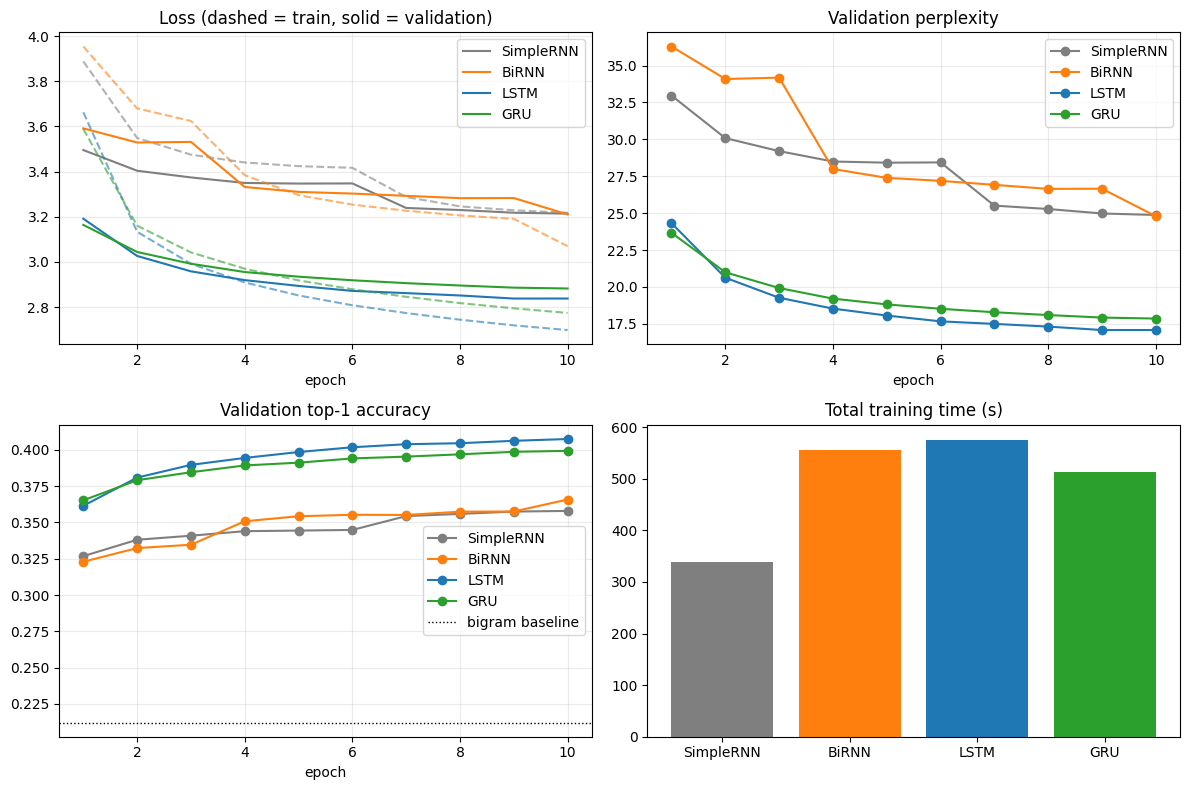

In [14]:
colors = {"SimpleRNN": "tab:gray", "BiRNN": "tab:orange", "LSTM": "tab:blue", "GRU": "tab:green"}
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for name, lg in logs.items():
    axes[0, 0].plot(lg.epoch, lg.train_loss, "--", color=colors[name], alpha=0.6)
    axes[0, 0].plot(lg.epoch, lg.val_loss, "-", color=colors[name], label=name)
    axes[0, 1].plot(lg.epoch, np.exp(lg.val_loss), "o-", color=colors[name], label=name)
    axes[1, 0].plot(lg.epoch, lg.val_acc, "o-", color=colors[name], label=name)
axes[1, 0].axhline(BASELINES.loc["Bigram lookup", "val"], color="k", ls=":", lw=1, label="bigram baseline")
axes[0, 0].set_title("Loss (dashed = train, solid = validation)")
axes[0, 1].set_title("Validation perplexity")
axes[1, 0].set_title("Validation top-1 accuracy")
for ax in axes.flat[:3]:
    ax.set_xlabel("epoch"); ax.grid(alpha=0.25); ax.legend()
axes[1, 1].bar(metrics.index, metrics["Total time (s)"], color=[colors[n] for n in metrics.index])
axes[1, 1].set_title("Total training time (s)")
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/training_comparison.png", dpi=110)
plt.show()

#### Observations (quantitative)

- **LSTM** is the best model on every test metric: lowest test loss (2.805) and perplexity (16.5), top-1 accuracy 41.3% and top-5 accuracy 68.3%. The **GRU** is close behind (perplexity 17.2, 40.7%, 67.7%). In other words, the LSTM guesses the exact next word about 4 times in 10 on stories it has never seen, and the right word is in its top 5 more than two thirds of the time.
- Both gated models are clearly ahead of the plain RNNs. Their test perplexity is 28 to 31% lower than the Simple RNN's (24.1) and the BiRNN's (24.0), and their accuracy is 3.5 to 5 points higher. Stories need the model to remember who the character is and what is happening, and the gates help carry that through the 16-token window.
- All four models beat both baselines by a wide margin. Always guessing *"."* gives 8.3% and the bigram lookup gives 21.3%. The LSTM is 20 points above the bigram model, and 5 times better than the trivial guess.
- The **BiRNN** ends up almost level with the Simple RNN (perplexity 24.0 vs 24.1, accuracy 37.1% vs 36.3%), even though it has 74% more parameters and takes 64% longer per epoch. It also has the biggest gap between training and test perplexity (14.4 vs 24.0), so the extra capacity mostly goes into fitting the training stories. Reading the window backwards adds very little for predicting the word that comes next.
- **Overfitting is mild overall.** With about 2.8 million training windows, the gap between training and test perplexity is small for every model (from 1.3x for the Simple RNN to 1.7x for the BiRNN), and the validation curves were still going down, or had only just levelled off, at the end.
- **No model stopped early.** All four used the full 10 epochs. The LSTM's best epoch was 9 (epoch 10 gave the same validation loss), and the other three were best at epoch 10, so more epochs would probably still help a little.
- **Learning-rate halving shows in the curves.** The Simple RNN had a flat epoch 6 and the BiRNN flat epochs 3 and 9. Each time the scheduler halved the learning rate, and the next epoch (7 for the Simple RNN, 4 and 10 for the BiRNN) shows a clear drop. The LSTM and GRU improved steadily, so their curves are smooth.
- **Time.** On the T4 the Simple RNN took 34 s per epoch, the GRU 51 s, the BiRNN 56 s and the LSTM 58 s. Training all four took 33 minutes.

### Text generation
The generator samples one word at a time from `softmax(logits / T)` and feeds it back as input. `<unk>` is masked out. Prompts are the same for all models.

Measures used alongside reading the outputs:
- **TTR / distinct-2**: unique words or bigrams over total (diversity)
- **rep-4**: fraction of 4-grams that repeat inside one sample (looping)
- **novel-4**: fraction of generated 4-grams that never appear in the training stories. Close to 0 means copying memorised phrases, close to 1 with low coherence usually means word salad
- **sentence ends**: average number of `. ! ?` per 50 words, a rough sign of whether it forms sentences
- **keeps character**: share of samples where the prompt's main character (Lily, Tom, the dog) is mentioned again, a simple check of contextual consistency

In [15]:
PROMPTS = [
    ("Once upon a time, there was a little girl named Lily. She", "lily"),
    ("One day, Tom went to the park with his mom and", "tom"),
    ("The little dog was very sad because", "dog"),
]
train_4grams = set()
for s in train_stories:
    train_4grams.update(zip(s, s[1:], s[2:], s[3:]))


@torch.no_grad()
def sample_text(model, prompt, n=50, temp=1.0):
    model.eval()
    ids = encode(clean_tokens(prompt))
    generated = []
    for _ in range(n):
        ctx = torch.tensor(ids[-CFG["seq_len"]:], device=DEVICE).unsqueeze(0)
        logits = model(ctx).squeeze(0).float()
        logits[0] = float("-inf")
        nxt = torch.multinomial(torch.softmax(logits / temp, -1), 1).item()
        ids.append(nxt)
        generated.append(idx2word[nxt])
    return generated


def pretty(words):
    s = " ".join(words)
    s = re.sub(r" ([.,!?])", r"\1", s)
    return re.sub(r"(^|[.!?] )([a-z])", lambda m: m.group(1) + m.group(2).upper(), s)


def text_stats(w, key):
    grams = lambda n: list(zip(*[w[i:] for i in range(n)]))
    g2, g4 = grams(2), grams(4)
    return {
        "TTR": len(set(w)) / len(w),
        "distinct-2": len(set(g2)) / len(g2),
        "rep-4": 1 - len(set(g4)) / len(g4),
        "novel-4": sum(g not in train_4grams for g in g4) / len(g4),
        "sentence ends": sum(t in ".!?" for t in w) * 50 / len(w),
        "keeps character": float(key in w),
    }

In [16]:
set_seed(11)
print("Same prompt, T = 0.7, all four models\n")
for p, _ in PROMPTS:
    print(">>", p)
    for name, m in trained.items():
        print(f"   {name:9s}: ...{pretty(sample_text(m, p, 40, 0.7))}")
    print()

Same prompt, T = 0.7, all four models

>> Once upon a time, there was a little girl named Lily. She
   SimpleRNN: ...Saw her small toy car and said, hi, mr. Brown, please. I love you, mom. I am sorry. I am sorry. I am sorry. I don't know. Maybe the
   BiRNN    : ...Was very hungry. She had to leave the safari behind her mom. She wished she had listened to her mom and they would play with her. But then, lily accidentally broke her red bottle. She
   LSTM     : ...Loved to play outside with her friends. One day, lily found a big box on the ground. She wanted to know what it was, so she asked her mom for help. Her mom showed her
   GRU      : ...Loved to play outside and explore the world around her. One day, she saw a big, green tree in the garden. She was so excited! She picked up the branches and put it in a

>> One day, Tom went to the park with his mom and
   SimpleRNN: ...Dad. He said they had a good day. They were happy and they danced together. They played together and had fun. Wh

#### Observations (qualitative)

Reading the T = 0.7 outputs side by side:

- **Coherence.** The gated models write the most story-like text. The LSTM continued the Lily prompt with *"Loved to play outside with her friends. One day, lily found a big box on the ground. She wanted to know what it was, so she asked her mom for help."*, which could pass for a real TinyStories opening. The GRU wrote *"Loved to play outside and explore the world around her. One day, she saw a big, green tree in the garden."*. The Simple RNN got stuck on *"I am sorry. I am sorry. I am sorry."*, and the BiRNN's sentences are grammatical but don't connect well (*"She had to leave the safari behind her mom"*).
- **Contextual consistency.** This is the weak point for all four. They keep the right *kind* of story (park, toys, mom and dad, a problem and a feeling), but the characters drift. In the Tom prompt the BiRNN switches to *"Lily was very excited"* after two sentences, and the LSTM brings in *"sara"* and *"Tim"*. A 16-token window is only one or two sentences, so once the name scrolls out of the window the model has no way to remember it.
- **Repetition.** At T = 0.7 it's mostly mild, with repeated story phrases like *"wanted to play with it"*. The Simple RNN is the exception and loops on short dialogue lines.
- **Diversity.** The LSTM and GRU use the widest range of words and events, while the plain RNNs fall back on the most common story phrases more often.

---
## Part (iii): Effect of sampling temperature
Four temperatures: 0.3 (conservative), 0.7, 1.0 (the model's own distribution) and 1.3 (flattened). Each (model, temperature, prompt) combination is sampled 6 times, 50 words each.

In [17]:
TEMPERATURES = [0.3, 0.7, 1.0, 1.3]
set_seed(99)
records, shown = [], {}
for name, m in trained.items():
    for T in TEMPERATURES:
        for p, key in PROMPTS:
            for rep in range(6):
                w = sample_text(m, p, 50, T)
                records.append({"model": name, "T": T, "prompt": p, **text_stats(w, key)})
                if rep == 0:
                    shown[(name, T, p)] = pretty(w)

with open(f"{SAVE_DIR}/generated_text_samples.txt", "w", encoding="utf-8") as fh:
    fh.write("TinyStories: generated samples (first of 6 per prompt)\n")
    for (name, T, p), txt in shown.items():
        fh.write(f"\n[{name} | T={T}] {p} ...\n{txt}\n")

p0 = PROMPTS[0][0]
for name in trained:
    print(f"===== {name} =====")
    for T in TEMPERATURES:
        print(f"T={T}: ...{shown[(name, T, p0)]}\n")

===== SimpleRNN =====
T=0.3: ...Loved to play outside in the sunshine. One day, she saw a big, red ball. She looked around and saw a big, scary dog. She was scared and wanted to explore. She asked her mom if she could have a snack. She

T=0.7: ...Saw a big lion and wanted to play with the butterfly. She said, no, a man, max said. What do you think? The boy was scared, but he did not want to play with. He asked his mom if he could play

T=1.0: ...Loved to play outside. She liked to count a story. One day, tom asked his friends to come out to the store, so he and his mom ate their lunch. They said, this is a great gift! They saw a big, harsh

T=1.3: ...Read a big and shiny one. Her mom said, playing with blocks together. Why are you very graceful spider? Mom asked. Yes, i are a pair but can we try to waste it to find our special strength piece! Tim exclaimed. But

===== BiRNN =====
T=0.3: ...Loved to play outside in the sunshine. One day, she went to the park with her mom and dad. She sa

In [18]:
for p, _ in PROMPTS[1:]:
    print(f"#### prompt: {p}")
    for T in TEMPERATURES:
        print(f"  T={T}")
        for name in trained:
            print(f"    {name:9s}: ...{shown[(name, T, p)]}")
    print()

#### prompt: One day, Tom went to the park with his mom and
  T=0.3
    SimpleRNN: ...Dad. He saw a big tree with lots of toys. He was very proud of him. He had never been on the couch. He was sad because he didn't know what to do. He asked his mom if he could have a snack. He
    BiRNN    : ...Dad. They saw a big slide with a big red nose. It was a big dog. It was red and shiny. It was a big, red ball. It was a big, shiny rock. It was a big, shiny rock. It
    LSTM     : ...Dad. They saw a big hill with lots of trees and flowers. They wanted to see what was inside. They saw a big tree with many leaves. They wanted to see what was inside. They saw a big tree with a hole in it.
    GRU      : ...Dad. He saw a big tree with many leaves. He wanted to climb it. He climbed up the tree and reached for the tree. But when he touched the branch, he saw a big tree. The bird was very scared. The bird wanted
  T=0.7
    SimpleRNN: ...Dad. He saw a big, dog, who was very naughty. He asked the man i

In [19]:
gen = pd.DataFrame(records)
temp_summary = gen.groupby(["model", "T"]).mean(numeric_only=True).round(3)
temp_summary = temp_summary.reindex(list(MODEL_CLASSES), level=0)
temp_summary.to_csv(f"{SAVE_DIR}/temperature_analysis.csv")
temp_summary

TTR  distinct-2  rep-4  novel-4  sentence ends  \
model     T                                                       
SimpleRNN 0.3  0.571       0.773  0.102    0.072          5.444   
          0.7  0.634       0.893  0.013    0.275          4.778   
          1.0  0.748       0.978  0.001    0.520          4.944   
          1.3  0.812       0.989  0.000    0.797          4.611   
BiRNN     0.3  0.550       0.759  0.106    0.052          5.667   
          0.7  0.641       0.888  0.018    0.216          4.833   
          1.0  0.706       0.955  0.006    0.476          4.333   
          1.3  0.804       0.993  0.000    0.811          3.778   
LSTM      0.3  0.600       0.824  0.099    0.050          4.944   
          0.7  0.668       0.926  0.008    0.184          4.500   
          1.0  0.750       0.974  0.000    0.441          4.278   
          1.3  0.786       0.991  0.000    0.710          4.333   
GRU       0.3  0.587       0.837  0.043    0.061          4.889   
          0.7  0.666       0.927  0.004    0.216          4.667   
          1.0  0.692       0.948  0.002    0.478          4.722   
          1.3  0.800       0.989  0.000    0.767          4.278   

               keeps character  
model     T                     
SimpleRNN 0.3            0.056  
          0.7            0.000  
          1.0            0.000  
          1.3            0.056  
BiRNN     0.3            0.167  
          0.7            0.222  
          1.0            0.222  
          1.3            0.167  
LSTM      0.3            0.111  
          0.7            0.167  
          1.0            0.222  
          1.3            0.111  
GRU       0.3            0.278  
          0.7            0.056  
          1.0            0.167  
          1.3            0.111

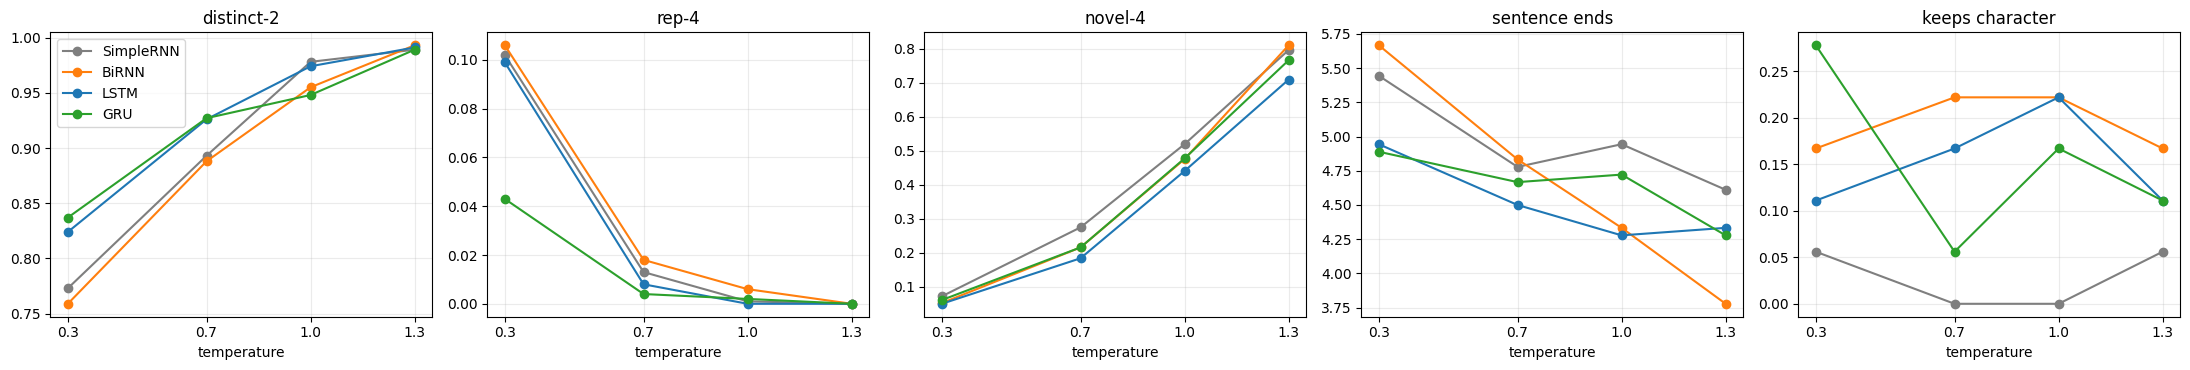

In [20]:
fig, axes = plt.subplots(1, 5, figsize=(22, 3.8))
for ax, col in zip(axes, ["distinct-2", "rep-4", "novel-4", "sentence ends", "keeps character"]):
    for name in MODEL_CLASSES:
        s = temp_summary.loc[name, col]
        ax.plot(s.index, s.values, "o-", color=colors[name], label=name)
    ax.set_title(col); ax.set_xlabel("temperature"); ax.set_xticks(TEMPERATURES); ax.grid(alpha=0.25)
axes[0].legend()
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/temperature_effects.png", dpi=110)
plt.show()

#### What temperature does

Dividing the logits by T before the softmax sharpens the distribution when T < 1 and flattens it when T > 1. The four temperatures show the full range:

- **T = 0.3: safe but loopy.** About 10% of 4-grams repeat inside a 50-word sample for three of the models (0.099 to 0.106), and only 5 to 7% of 4-grams are new, so the text is mostly stitched-together training phrases. Typical loops are *"It was a big, shiny rock. It was a big, shiny rock."* (BiRNN) and *"They wanted to see what was inside. They saw a big tree ... They wanted to see what was inside."* (LSTM). The **GRU** is the exception: it repeats far less (0.043) and writes the most sensible low-temperature text, e.g. *"He lost his ball. He wanted to play with the ball, but he didn't know what to do. He asked his mom if he could go and his mom said yes."*
- **T = 0.7: the best balance.** Repetition almost disappears (rep-4 0.004 to 0.018), distinct-2 rises to about 0.89 to 0.93, and roughly 20% of 4-grams are new. Sentences are still grammatical and form small scenes: *"They saw a big slide and wanted to play with it. They asked their mom if they could go and see the penguins."* (LSTM). The GRU (distinct-2 0.927, rep-4 0.004) and LSTM (0.926, 0.008) are the most varied and least repetitive here.
- **T = 1.0: creative but shaky.** About 44 to 52% of 4-grams are new. Some samples are still good (*"She looked everywhere, but she couldn't find it. She began to cry, but then she remembered her mom's warning."*, GRU), but others mix characters and objects that don't fit together (*"Max was so happy he could move to the soft water on her hand"*, LSTM).
- **T = 1.3: word salad.** 71 to 81% of 4-grams are new and the grammar breaks down (*"Mama brought peter make mama with those resist of them because parent were a yummy leak"*, GRU). The number of sentence endings also drops, especially for the BiRNN (3.8 per 50 words vs 5.7 at T = 0.3), as sentences turn into long run-ons.

**Contextual consistency across temperatures.** The *keeps character* score is low everywhere (0 to 0.28), which matches the reading above: with a 16-token context the main character is usually forgotten after a couple of sentences. It is measured on only 18 samples per setting, so the numbers are noisy and don't show a clear trend with temperature. The GRU at T = 0.3 has the highest value (0.278), and the Simple RNN is the worst at every temperature (0 to 0.056).

Overall: **low temperature means coherent but repetitive and copied text, and high temperature means varied but incoherent text.** Because TinyStories is so regular, the models are confident at most positions and the text stays readable up to about T = 0.7. **T around 0.7** gives the best mix of fluency, variety and low repetition for this dataset.

---
### Run summary
Collects the key numbers and writes them to `results_summary.md` for the README.

In [21]:
def md(df):
    try:
        return df.to_markdown()
    except ImportError:
        return "```\n" + df.to_string() + "\n```"

t07 = temp_summary.xs(0.7, level="T")
lines = [
    "# Run summary (TinyStories)\n", f"device: {DEVICE}\n",
    "## Model metrics\n", md(metrics.round(4)), "\n",
    "## Baselines (top-1 accuracy)\n", md(BASELINES), "\n",
    "## Temperature analysis\n", md(temp_summary), "\n",
    f"- lowest test perplexity: **{metrics['Test PPL'].idxmin()}** ({metrics['Test PPL'].min():.2f})",
    f"- highest test accuracy: **{metrics['Test top-1 acc'].idxmax()}** ({metrics['Test top-1 acc'].max():.3f})",
    f"- at T=0.7 most diverse: **{t07['distinct-2'].idxmax()}**, least repetitive: **{t07['rep-4'].idxmin()}**",
    f"- total training time: {metrics['Total time (s)'].sum() / 60:.1f} min",
]
with open(f"{SAVE_DIR}/results_summary.md", "w", encoding="utf-8") as fh:
    fh.write("\n".join(lines))
print("\n".join(lines[-4:]))

- lowest test perplexity: **LSTM** (16.53)
- highest test accuracy: **LSTM** (0.413)
- at T=0.7 most diverse: **GRU**, least repetitive: **GRU**
- total training time: 33.0 min


---
## Conclusion

**Best model for this dataset: LSTM** (sampled at a temperature of about 0.7), with the GRU a close second.

- It has the best held-out numbers of the four: test loss 2.805, perplexity 16.5, top-1 accuracy 41.3% and top-5 accuracy 68.3%. That is 20 points above the bigram baseline (21.3%) and 5 times the most-frequent-token baseline (8.3%).
- Its stories at T = 0.7 are the most coherent: grammatical sentences that form small scenes, with low repetition (rep-4 0.008) and high diversity (distinct-2 0.926).
- Its validation loss only levelled off at the very end (best epoch 9, epoch 10 the same), so it used the full training budget well.

The GRU is only slightly behind (perplexity 17.2, 40.7% accuracy). It is about 11% faster per epoch (51 s vs 58 s), it repeats the least at low temperatures, and it is marginally more varied at T = 0.7, so it is a good choice when training time matters. The Simple RNN is the fastest but clearly weaker, and loops on short phrases. The Bidirectional RNN is the least suited to the task: it has the most parameters, and its backward pass over the context doesn't help predict a word that comes *after* the context, so it only matches the Simple RNN despite costing much more.

All four models share the same main limitation: with a 16-token window they keep the style of a story but lose track of the characters after a sentence or two.

Saved outputs (in `/kaggle/working`, and in the `results/` and `samples/` folders of the repository): `model_metrics.csv`, `temperature_analysis.csv`, `results_summary.md`, `generated_text_samples.txt` and the figures.